# **Settings**

In [ ]:
# general purpose libraries
import glob
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

# used to manipulate the data sets
from pandas import DataFrame, read_csv
import pandas as pd 

# used for cleaning the dataset from unnecessary words
import nltk
nltk.download('stopwords')
nltk.download('punkt')
from nltk import bigrams
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer

import re
from collections import Counter

# visualization libraries
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# vectorization libraries
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec

# classification libraries
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.metrics import f1_score, accuracy_score

# ignore warnings
import warnings 
warnings.simplefilter(action='ignore', category=FutureWarning) 
warnings.filterwarnings('ignore', 'Solver terminated early.*')

# enable inline plotting
%matplotlib inline

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


# **1. Preprocessing / Text cleaning**

In [ ]:
# imported contractions list from http://stackoverflow.com/questions/19790188/expanding-english-language-contractions-in-python
contractions = {
"ain't": "are not",
"aren't": "are not",
"can't": "cannot",
"can't've": "cannot have",
"'cause": "because",
"could've": "could have",
"couldn't": "could not",
"couldn't've": "could not have",
"didn't": "did not",
"doesn't": "does not",
"don't": "do not",
"hadn't": "had not",
"hadn't've": "had not have",
"hasn't": "has not",
"haven't": "have not",
"he'd": "he would",
"he'd've": "he would have",
"he'll": "he will",
"he'll've": "he will have",
"he's": "he is",
"how'd": "how did",
"how'd'y": "how do you",
"how'll": "how will",
"how's": "how is",
"i'd": "I would",
"i'd've": "I would have",
"i'll": "I will",
"i'll've": "I will have",
"i'm": "I am",
"i've": "I have",
"isn't": "is not",
"it'd": "it would",
"it'd've": "it would have",
"it'll": "it will",
"it'll've": "it will have",
"it's": "it is",
"let's": "let us",
"ma'am": "madam",
"mayn't": "may not",
"might've": "might have",
"mightn't": "might not",
"mightn't've": "might not have",
"must've": "must have",
"mustn't": "must not",
"mustn't've": "must not have",
"needn't": "need not",
"needn't've": "need not have",
"o'clock": "of the clock",
"oughtn't": "ought not",
"oughtn't've": "ought not have",
"shan't": "shall not",
"sha'n't": "shall not",
"shan't've": "shall not have",
"she'd": "she would",
"she'd've": "she would have",
"she'll": "she will",
"she'll've": "she will have",
"she's": "she is",
"should've": "should have",
"shouldn't": "should not",
"shouldn't've": "should not have",
"so've": "so have",
"so's": "so is",
"that'd": "that would",
"that'd've": "that would have",
"that's": "that is",
"there'd": "there would",
"there'd've": "there would have",
"there's": "there is",
"they'd": "they would",
"they'd've": "they would have",
"they'll": "they will",
"they'll've": "they will have",
"they're": "they are",
"they've": "they have",
"to've": "to have",
"wasn't": "was not",
"we'd": "we would",
"we'd've": "we would have",
"we'll": "we will",
"we'll've": "we will have",
"we're": "we are",
"we've": "we have",
"weren't": "were not",
"what'll": "what will",
"what'll've": "what will have",
"what're": "what are",
"what's": "what is",
"what've": "what have",
"when's": "when is",
"when've": "when have",
"where'd": "where did",
"where's": "where is",
"where've": "where have",
"who'll": "who will",
"who'll've": "who will have",
"who's": "who is",
"who've": "who have",
"why's": "why is",
"why've": "why have",
"will've": "will have",
"won't": "will not",
"won't've": "will not have",
"would've": "would have",
"wouldn't": "would not",
"wouldn't've": "would not have",
"y'all": "you all",
"y'all'd": "you all would",
"y'all'd've": "you all would have",
"y'all're": "you all are",
"y'all've": "you all have",
"you'd": "you would",
"you'd've": "you would have",
"you'll": "you will",
"you'll've": "you will have",
"you're": "you are",
"you've": "you have"
}


# function for replacing contractions with their longer forms
def decontracted(sentence):
  for word in sentence.split():
    if word in contractions:
      sentence = sentence.replace(word, contractions[word])
  return sentence


# ways of cleaning and preprocessing the textual data applied:
# lower case, remove contractions & special characters, tokenization
def preprocess(sentence):
  # remove unwanted characters
  sentence = str(sentence).lower().replace(r'[^\w\s]+', '') 

  # remove contractions
  sentence = decontracted(sentence)

  # format words     
  sentence   = re.sub(r'https\s+', '', sentence) 
  sentence = re.sub(r'\'s', '', sentence)   # e.g. trump's -> trump
  sentence = re.sub(r'u\.k\.', 'uk', sentence)
  sentence = re.sub(r'u\.s\.', 'us', sentence) 
  sentence = re.sub(r'u\.n\.', 'un', sentence) 
     
  tokenizer = RegexpTokenizer(r'\w+')
  tokens = tokenizer.tokenize(sentence)    
  filtered_words = [w for w in tokens]
  return " ".join(filtered_words)

In [ ]:
# create dataframes from datasets
df = read_csv(glob.glob('**/True.csv', recursive=True)[0])
df2 = read_csv(glob.glob('**/Fake.csv', recursive=True)[0])

# remove rows that contain empty cells 
df = df.dropna()
df2 = df2.dropna()

# remove punctuations from 'title' and 'text' columns
df.title = df.title.map(lambda s: preprocess(s)) 
df.text = df.text.map(lambda s: preprocess(s)) 
df2.title = df2.title.map(lambda s: preprocess(s)) 
df2.text = df2.text.map(lambda s: preprocess(s)) 

# **2. Data analysis**

## **2.a**

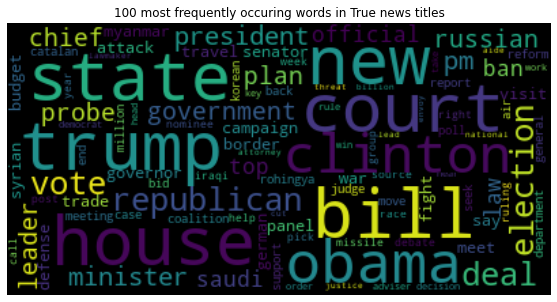

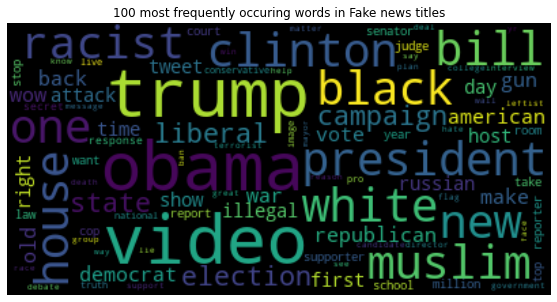

In [ ]:
df_list = [df.title, df2.title]
stop_words = set(stopwords.words('english'))

for i in range(len(df_list)):
  # get all titles
  titles = df_list[i]

  # create a list of strings, one for each title
  titles_list = [title for title in titles]

  # create a string with all titles 
  titles_string = ' '.join(titles_list)  

  # filter out stopwords  
  words = [word for word in titles_string.split() if not word in stop_words]

  # create a dataframe out of the filtered tokens
  results = Counter(words)
  q1 = DataFrame(results.items(), columns=['words', 'counts'])
  q1 = q1.sort_values('counts', ascending = False)
  wordcloud = WordCloud(max_font_size=50, min_font_size=5, max_words=100).generate(' '.join(q1['words']))
  plt.figure(figsize=(10,5))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.axis('off')
  if i < 1:
    plt.title('100 most frequently occuring words in True news titles')
  else:
    plt.title('100 most frequently occuring words in Fake news titles')
  plt.show()

## **2.b**

,mean,type,label
0,63,Title,True
1,91,Title,Fake
2,"2,321",Text,True
3,"2,489",Text,Fake


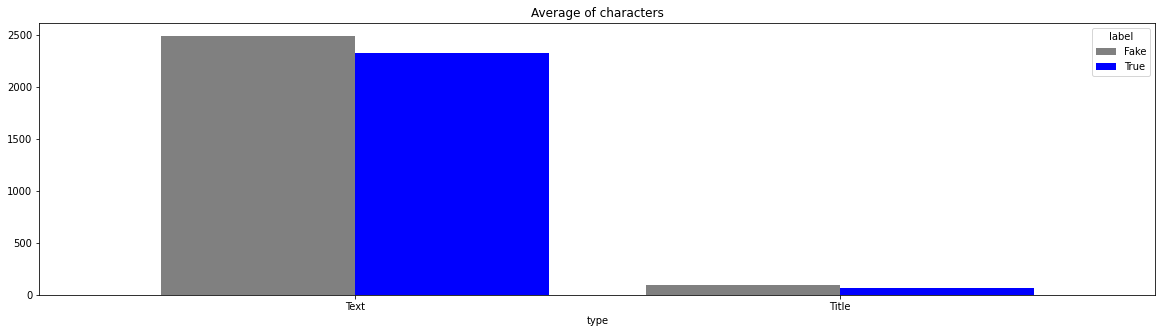

In [ ]:
q2 = DataFrame()
q2['mean'] = [np.mean(df.title.str.len()), np.mean(df2.title.str.len()), np.mean(df.text.str.len()), np.mean(df2.text.str.len())]
q2['type'] = ['Title', 'Title', 'Text', 'Text']
q2['label'] = ['True', 'Fake', 'True', 'Fake']

q2.pivot(index='type', columns='label', values='mean').plot.bar(figsize=(20, 5), width=0.8, color=['grey', 'blue'], title='Average of characters')
plt.xticks(rotation=360)
pd.options.display.float_format = '{:,.0f}'.format
q2

## **2.c**

,counts,label,type
0,"1,371,601",True,Title
1,"49,736,249",True,Text
2,"2,165,232",Fake,Title
3,"58,472,396",Fake,Text


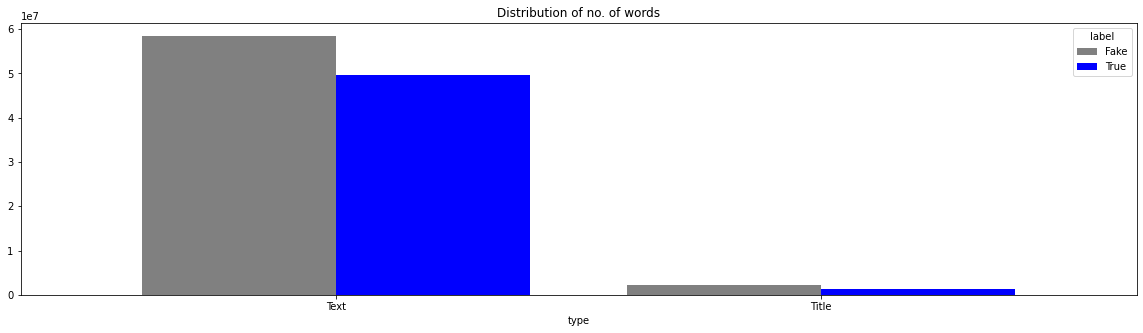

In [ ]:
df_list = [df.title, df.text, df2.title, df2.text]
texts = {'True News Titles', 'True News Texts', 'Fake News Titles', 'Fake News Texts'}
types = ['Title', 'Text', 'Title', 'Text']
q3 = DataFrame()

for i in range(len(df_list)): 
  # get all rows for each column
  columns = df_list[i]

  # create a list of strings, one for each column
  columns_list = [string for string in columns]

  # create a string with all elements of the column 
  columns_string = ' '.join(columns_list) 

  if i < 2:
    new_row = {'type': types[i], 'counts': len(columns_string), 'label': 'True'}
  else: 
    new_row = {'type': types[i], 'counts': len(columns_string), 'label': 'Fake'}
  # append row to the dataframe
  q3 = q3.append(new_row, ignore_index=True)
   
q3.pivot(index='type', columns='label', values='counts').plot.bar(figsize=(20, 5), width=0.8, color=['grey', 'blue'], title='Distribution of no. of words')
plt.xticks(rotation=360)
pd.options.display.float_format = '{:,.0f}'.format
q3

## **2.d**

,counts,label,type
0,"1,218,191",True,Title
1,"37,200,787",True,Text
2,"1,754,795",Fake,Title
3,"41,332,543",Fake,Text


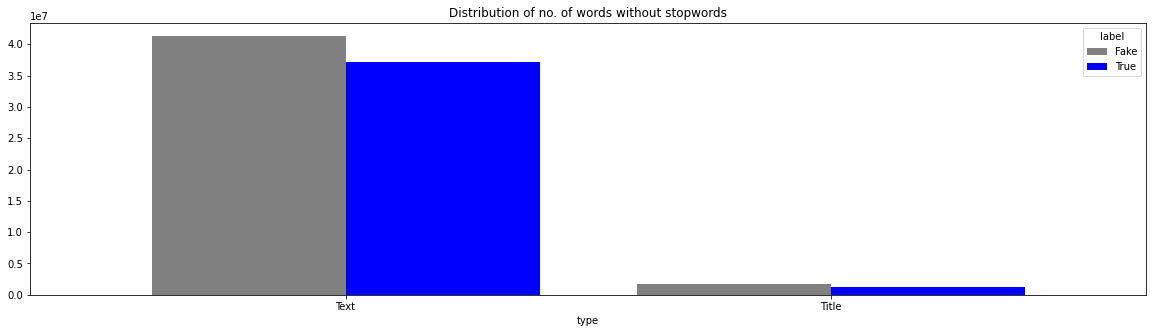

In [ ]:
df_list = [df.title, df.text, df2.title, df2.text]
texts = {'True News Titles', 'True News Texts', 'Fake News Titles', 'Fake News Texts'}
types = ['Title', 'Text', 'Title', 'Text']
q4 = DataFrame()
stop_words = set(stopwords.words('english'))

for i in range(len(df_list)): 
  # get all rows for each column
  columns = df_list[i]

  # create a list of strings, one for each column
  columns_list = [string for string in columns]

  # create a string with all elements of the column 
  columns_string = ' '.join(columns_list) 

  # filter out stopwords    
  filtered_list = [word for word in columns_string.split() if not word in stop_words]
  new_string = ' '.join(filtered_list) 

  if i < 2:
    new_row = {'type': types[i], 'counts': len(new_string), 'label': 'True'}
  else: 
    new_row = {'type': types[i], 'counts': len(new_string), 'label': 'Fake'}
  # append row to the dataframe
  q4 = q4.append(new_row, ignore_index=True)
   
q4.pivot(index='type', columns='label', values='counts').plot.bar(figsize=(20, 5), width=0.8, color=['grey', 'blue'], title='Distribution of no. of words without stopwords')
plt.xticks(rotation=360)
pd.options.display.float_format = '{:,.0f}'.format
q4

## **2.e**

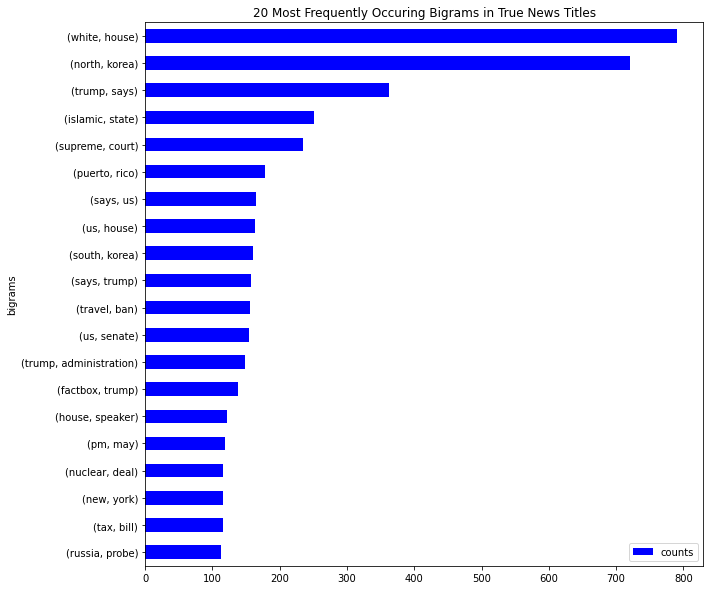

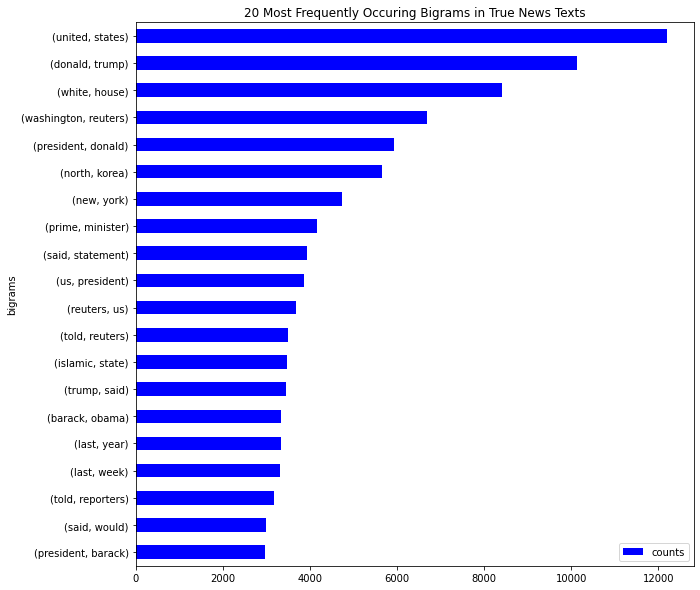

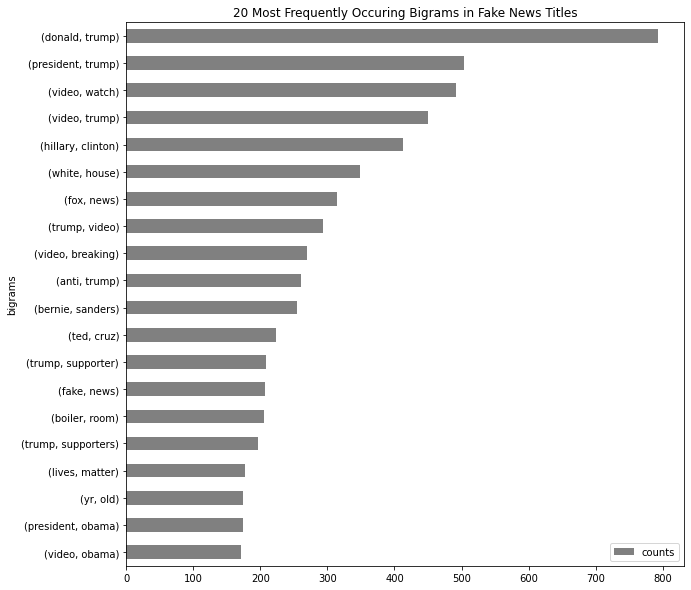

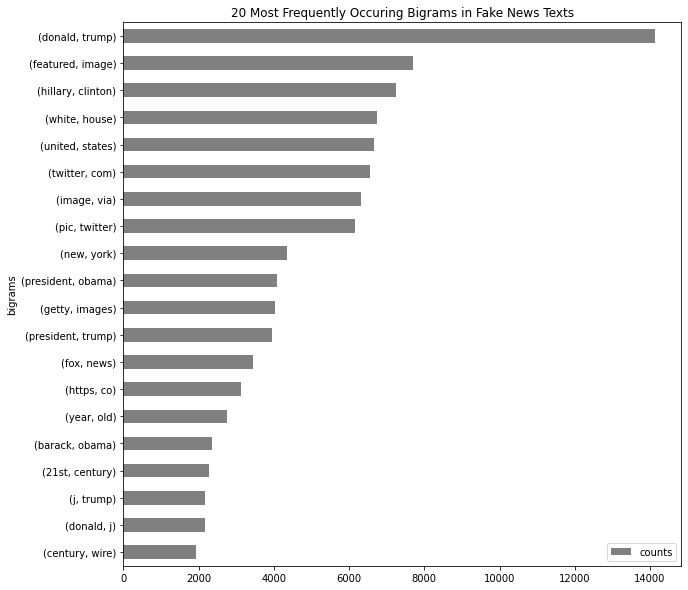

In [ ]:
df_list = [df.title, df.text, df2.title, df2.text]
texts = ['True News Titles', 'True News Texts', 'Fake News Titles', 'Fake News Texts']
stop_words = set(stopwords.words('english'))

for i in range(len(df_list)):
  # get all rows for each column
  columns = df_list[i]

  # create a list of strings, one for each column
  columns_list = [string for string in columns]

  # create a string with all elements of the column 
  columns_string = ' '.join(columns_list) 

  # filter out stopwords    
  filtered_list = [word for word in columns_string.split() if not word in stop_words]
  new_string = ' '.join(filtered_list) 
  words = new_string.split()

  # create a Counter set for the bigrams
  results = Counter(bigrams(words))
  results = dict(results.most_common(20))
  
  q5 = DataFrame(results.items(), columns=['bigrams', 'counts'])
  q5 = q5.sort_values('counts')
  if i < 2:
    q5.plot.barh(x='bigrams', y='counts', figsize=(10, 10), color='blue', title='20 Most Frequently Occuring Bigrams in ' + texts[i])
  else: 
    q5.plot.barh(x='bigrams', y='counts', figsize=(10, 10), color='grey', title='20 Most Frequently Occuring Bigrams in ' + texts[i])

# **3. Create training and testing set**

In [ ]:
# create new dataframes out of the first ones
dfs = df
dfs2 = df2

dfs['label'] = '1'
dfs2['label'] = '0'

# choose 70% of the trues' and fakes' records for the train set
dfs[:round(len(df)*0.7)].to_csv('train.csv', index=False)
dfs2[:round(len(df2)*0.7)].to_csv('train.csv', mode='a', index=False, header=False)

# leave the rest for the test set
dfs[round(len(df)*0.7):].to_csv('test.csv', index=False)
dfs2[round(len(df2)*0.7):].to_csv('test.csv', mode='a', index=False, header=False)

# **4. Classification**


### **Vectorization Part**

#### Count/Tfidf-Vectorizer for BoW

In [ ]:
dftrain = read_csv(glob.glob('train.csv')[0])
dftest = read_csv(glob.glob('test.csv')[0])

bow_vectorizer = CountVectorizer(ngram_range=(1, 1), max_features=2000, max_df = 0.5, min_df = 0.01, stop_words='english')
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 1), max_features=2000, max_df = 0.5, min_df = 0.01, stop_words='english')

# train  
X_tr_bow = bow_vectorizer.fit_transform(dftrain['title'].apply(lambda x: np.str_(x)) + dftrain['text'].apply(lambda x: np.str_(x)) + dftrain['subject'].apply(lambda x: np.str_(x))).toarray() 
X_tr_tfidf = tfidf_vectorizer.fit_transform(dftrain['title'].apply(lambda x: np.str_(x)) + dftrain['text'].apply(lambda x: np.str_(x)) + dftrain['subject'].apply(lambda x: np.str_(x))).toarray()

# test 
X_te_bow = bow_vectorizer.transform(dftest['title'].apply(lambda x: np.str_(x)) + dftest['text'].apply(lambda x: np.str_(x)) + dftest['subject'].apply(lambda x: np.str_(x))).toarray() 
X_te_tfidf = tfidf_vectorizer.transform(dftest['title'].apply(lambda x: np.str_(x)) + dftest['text'].apply(lambda x: np.str_(x)) + dftest['subject'].apply(lambda x: np.str_(x))).toarray()

y_tr = dftrain['label']
y_te = dftest['label']

#### Data Normalization

In [ ]:
# Count-Vectorizer
means = np.mean(X_tr_bow, axis=0)
stds = np.std(X_tr_bow, axis=0)
X_tr_bow = (X_tr_bow - means)/stds
X_te_bow = (X_te_bow - means)/stds

# Tfidf-Vectorizer
means = np.mean(X_tr_tfidf, axis=0)
stds = np.std(X_tr_tfidf, axis=0)
X_tr_tfidf = (X_tr_tfidf - means)/stds
X_te_tfidf = (X_te_tfidf - means)/stds

#### Word2Vec


In [ ]:
stop_words = set(stopwords.words('english'))
tokens = [word.split() for word in (dftrain['title'].apply(lambda x: np.str_(x)) + dftrain['text'].apply(lambda x: np.str_(x)) + dftrain['subject'].apply(lambda x: np.str_(x))) if not word.split in stop_words]
trainmodel = Word2Vec(
              tokens,
              size=500,   # desired no. of features/independent variables
              window=5,   # context window size
              min_count=2,
              sg=0,       
              hs=0,
              negative=5, # for negative sampling
              workers=2,  # no. of cores
              seed=32)
trainmodel.train(tokens, total_examples=trainmodel.corpus_count, epochs=15); # train the model

In [ ]:
# create document vectors by averaging word vectors & remove out-of-vocabulary words
def document_vector(doc):
  doc = [word for word in doc if word in trainmodel.wv.vocab]
  return np.mean(trainmodel[doc], axis=0)

X_tr_w2v = (dftrain['title'].apply(lambda x: np.str_(x)) + dftrain['text'].apply(lambda x: np.str_(x)) + dftrain['subject'].apply(lambda x: np.str_(x))).apply(document_vector)
X_te_w2v = (dftest['title'].apply(lambda x: np.str_(x)) + dftest['text'].apply(lambda x: np.str_(x)) + dftest['subject'].apply(lambda x: np.str_(x))).apply(document_vector)

X_tr_w2v = list(X_tr_w2v)
X_te_w2v = list(X_te_w2v)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: DeprecationWarning: Call to deprecated `__getitem__` (Method will be removed in 4.0.0, use self.wv.__getitem__() instead).
  after removing the cwd from sys.path.


### **Classifiers**

In [ ]:
 def logistic_classify(X_train, y_train, X_test, y_test, description):
  model = LogisticRegression(C=1.0, max_iter=500)
  model.fit(X_train, y_train)
  test_pred = model.predict(X_test)
  accuracy = accuracy_score(y_test, test_pred)
  f1 = f1_score(y_test, test_pred) 
  print('Logistic Regression with', description, '\nAccuracy: %0.2f' % (accuracy * 100), '%', '\nF1 score: %0.2f' % (f1 * 100), '%\n')
  return accuracy, f1

def bayes_classify(X_train, y_train, X_test, y_test, description):
  model = GaussianNB()
  model.fit(X_train, y_train)
  test_pred = model.predict(X_test)
  accuracy = accuracy_score(y_test, test_pred)
  f1 = f1_score(y_test, test_pred)
  print('Naive Bayes with', description, '\nAccuracy: %0.2f' % (accuracy * 100), '%', '\nF1 score: %0.2f' % (f1 * 100), '%\n')
  return accuracy, f1

def svm_classify(X_train, y_train, X_test, y_test, description, kernel):
  if kernel == 'rbf':
    gsc = GridSearchCV(SVC(), param_grid={'C': [1, 10, 1000], 'gamma': ['auto'], 'kernel': ['rbf'], 'max_iter': [10000], 'tol': [0.1]}, cv=3, refit=True)
    gsc.fit(X_train, y_train)    
    model = gsc.best_estimator_
  else:
    model = LinearSVC(random_state=42, dual=False).fit(X_train, y_train)
  test_pred = model.predict(X_test)
  accuracy = accuracy_score(y_test, test_pred)
  f1 = f1_score(y_test, test_pred)
  print('Support Vector Machines (', kernel, ') with', description, '\nAccuracy: %0.2f' % (accuracy * 100), '%', '\nF1 score: %0.2f' % (f1 * 100), '%\n')
  return accuracy, f1

def rf_classify(X_train, y_train, X_test, y_test, description):
  model = RandomForestClassifier()
  model.fit(X_train, y_train)
  test_pred = model.predict(X_test)
  accuracy = accuracy_score(y_test, test_pred)
  f1 = f1_score(y_test, test_pred)
  print('Random Forest with', description, '\nAccuracy: %0.2f' % (accuracy * 100), '%', '\nF1 score: %0.2f' % (f1 * 100), '%\n')
  return accuracy, f1

#### **Logistic Regression**


In [ ]:
lr_bow_ac, lr_bow_f1 = logistic_classify(X_tr_bow, y_tr, X_te_bow, y_te, 'BoW')
lr_tfidf_ac, lr_tfidf_f1 = logistic_classify(X_tr_tfidf, y_tr, X_te_tfidf, y_te, 'tf-idf')
lr_w2v_ac, lr_w2v_f1 = logistic_classify(X_tr_w2v, y_tr, X_te_w2v, y_te, 'word2vec')

Logistic Regression with BoW 
Accuracy: 98.06 % 
F1 score: 97.98 %

Logistic Regression with tf-idf 
Accuracy: 97.87 % 
F1 score: 97.78 %

Logistic Regression with word2vec 
Accuracy: 74.42 % 
F1 score: 75.07 %



#### **Naive Bayes**

In [ ]:
bayes_bow_ac, bayes_bow_f1 = bayes_classify(X_tr_bow, y_tr, X_te_bow, y_te, 'BoW')
bayes_tfidf_ac, bayes_tfidf_f1 = bayes_classify(X_tr_tfidf, y_tr, X_te_tfidf, y_te, 'tf-idf')
bayes_w2v_ac, bayes_w2v_f1 = bayes_classify(X_tr_w2v, y_tr, X_te_w2v, y_te, 'word2vec')

Naive Bayes with BoW 
Accuracy: 86.98 % 
F1 score: 87.55 %

Naive Bayes with tf-idf 
Accuracy: 89.08 % 
F1 score: 89.36 %

Naive Bayes with word2vec 
Accuracy: 69.97 % 
F1 score: 72.58 %



#### **Support Vector Machines with rbf kernel**


In [ ]:
rbf_bow_ac, rbf_bow_f1 = svm_classify(X_tr_bow, y_tr, X_te_bow, y_te, 'BoW', 'rbf')

Support Vector Machines ( rbf ) with BoW 
Accuracy: 98.33 % 
F1 score: 98.25 %



In [ ]:
rbf_tfidf_ac, rbf_tfidf_f1 = svm_classify(X_tr_tfidf, y_tr, X_te_tfidf, y_te, 'tf-idf', 'rbf')

Support Vector Machines ( rbf ) with tf-idf 
Accuracy: 98.49 % 
F1 score: 98.43 %



In [ ]:
rbf_w2v_ac, rbf_w2v_f1 = svm_classify(X_tr_w2v, y_tr, X_te_w2v, y_te, 'word2vec', 'rbf')

Support Vector Machines ( rbf ) with word2vec 
Accuracy: 73.18 % 
F1 score: 75.21 %



#### **Support Vector Machines with linear kernel**

In [ ]:
svml_bow_ac, svml_bow_f1 = svm_classify(X_tr_bow, y_tr, X_te_bow, y_te, 'BoW', 'linear')
svml_tfidf_ac, svml_tfidf_f1 = svm_classify(X_tr_tfidf, y_tr, X_te_tfidf, y_te, 'tf-idf', 'linear')
svml_w2v_ac, svml_w2v_f1 = svm_classify(X_tr_w2v, y_tr, X_te_w2v, y_te, 'word2vec', 'linear')

Support Vector Machines ( linear ) with BoW 
Accuracy: 97.87 % 
F1 score: 97.77 %

Support Vector Machines ( linear ) with tf-idf 
Accuracy: 97.60 % 
F1 score: 97.50 %

Support Vector Machines ( linear ) with word2vec 
Accuracy: 74.48 % 
F1 score: 75.14 %



#### **Random Forests**


In [ ]:
rf_bow_ac, rf_bow_f1 = rf_classify(X_tr_bow, y_tr, X_te_bow, y_te, 'BoW')
rf_tfidf_ac, rf_tfidf_f1 = rf_classify(X_tr_tfidf, y_tr, X_te_tfidf, y_te, 'tf-idf')
rf_w2v_ac, rf_w2v_f1 = rf_classify(X_tr_w2v, y_tr, X_te_w2v, y_te, 'word2vec')

Random Forest with BoW 
Accuracy: 98.69 % 
F1 score: 98.64 %

Random Forest with tf-idf 
Accuracy: 98.73 % 
F1 score: 98.68 %

Random Forest with word2vec 
Accuracy: 81.76 % 
F1 score: 81.12 %



 # *Conclusion*



In [ ]:
accuracies = DataFrame(columns = ['Bag Of Words','TF-IDF','Word2Vec'], index = ['Logistic Regression','Naive Bayes', 'SVM (rbf)', 'SVM (linear)', 'Random Forest'])
accuracies['Bag Of Words'] = [lr_bow_ac, bayes_bow_ac, rbf_bow_ac, svml_bow_ac, rf_bow_ac]
accuracies['TF-IDF'] = [lr_tfidf_ac,  bayes_tfidf_ac, rbf_tfidf_ac, svml_tfidf_ac, rf_tfidf_ac]
accuracies['Word2Vec'] = [lr_w2v_ac, bayes_w2v_ac, rbf_w2v_ac, svml_w2v_ac, rf_w2v_ac]
print('Accuracy')
accuracies

Accuracy


,Bag Of Words,TF-IDF,Word2Vec
Logistic Regression,0.980622,0.978692,0.744153
Naive Bayes,0.869775,0.890786,0.699681
SVM (rbf),0.983295,0.984928,0.731829
SVM (linear),0.978692,0.976019,0.744821
Random Forest,0.986859,0.989160,0.817433


In [ ]:
f1s = DataFrame(columns = ['Bag Of Words','TF-IDF','Word2Vec'], index = ['Logistic Regression','Naive Bayes', 'SVM (rbf)', 'SVM (linear)', 'Random Forest'])
f1s['Bag Of Words'] = [lr_bow_f1, bayes_bow_f1, rbf_bow_f1, svml_bow_f1, rf_bow_f1]
f1s['TF-IDF'] = [lr_tfidf_f1,  bayes_tfidf_f1, rbf_tfidf_f1, svml_tfidf_f1, rf_tfidf_f1]
f1s['Word2Vec'] = [lr_w2v_f1, bayes_w2v_f1, rbf_w2v_f1, svml_w2v_f1, rf_w2v_f1]
print('F1 Score')
f1s

F1 Score


,Bag Of Words,TF-IDF,Word2Vec
Logistic Regression,0.979766,0.977750,0.750651
Naive Bayes,0.875462,0.893599,0.725781
SVM (rbf),0.982530,0.984299,0.752059
SVM (linear),0.977740,0.974959,0.751392
Random Forest,0.986301,0.988679,0.812161


From the results presented above we can conclude that Random Forest is the best classifier out of the four. It reaches the highest accuracy score, 98.69 % and f1 score, 98.64 %, with Support Vector Machine (rbf kernel) to follow with 98.33 % and 98.25 % accuracy and f1 score, respectively. On the other hand we achieve the lowest scores with Naive Bayes, because -as we know- it assumes the features are independent and the probabilities are incorrect if this assumption is not correct.

Furthermore, we observe that Bag of Words and TF-IDF vectorization methods do not differ much at scores, which -I think- is to be expected as they are very similar methods. Additionally, these methods seem to outperform Word Embeddings, the scores of which did not exceed 82 %. One possible reason that I think this happened is because of the size of the dataset -Word2Vec was not able to capture world relationship in the embedding space with limited information. One way to solve this would be to train the model on a much larger corpus or even trying pre-trained embeddings.

# **5. Beat the Benchmark**

In [ ]:
def rf_benchmark(X_train, y_train, X_test, y_test, description):
  param_grid = {'n_estimators': [100, 500, 1000],    # number of trees in the forest
                'max_features': ['auto', 'sqrt', 'log2']}    # number of features to consider when looking for the best split

  gsc = RandomizedSearchCV(RandomForestClassifier(), param_distributions=param_grid, cv=3, n_iter=9, random_state=42)

  gsc.fit(X_train, y_train)    
  model = gsc.best_estimator_ 
  test_pred = model.predict(X_test)
  accuracy = accuracy_score(y_test, test_pred)
  f1 = f1_score(y_test, test_pred)
  print('Random Forest with', description, '\nAccuracy: %0.2f' % (accuracy * 100), '%', '\nF1 score: %0.2f' % (f1 * 100), '%\n')
  return accuracy, f1

In [ ]:
bench_ac, bench_f1 = rf_benchmark(X_tr_bow, y_tr, X_te_bow, y_te, 'BoW')
print('Base Accuracy vs Random Search {:0.4f}%'.format( 100 * (bench_ac - rf_bow_ac) / rf_bow_ac))
print('Base F1 score vs Random Search {:0.4f}%\n\n'.format( 100 * (bench_f1 - rf_bow_f1) / rf_bow_f1))

Random Forest with BoW 
Accuracy: 98.70 % 
F1 score: 98.65 %

Base Accuracy vs Random Search 0.0075%
Base F1 score vs Random Search 0.0094%




In [ ]:
bench_ac, bench_f1 = rf_benchmark(X_tr_tfidf, y_tr, X_te_tfidf, y_te, 'tf-idf')
print('Base Accuracy vs Random Search {:0.4f}%'.format( 100 * (bench_ac - rf_tfidf_ac) / rf_tfidf_ac))
print('Base F1 score vs Random Search {:0.4f}%\n\n'.format( 100 * (bench_f1 - rf_tfidf_f1) / rf_tfidf_f1))

Random Forest with tf-idf 
Accuracy: 98.92 % 
F1 score: 98.87 %

Base Accuracy vs Random Search 0.1880%
Base F1 score vs Random Search 0.1947%




In [ ]:
bench_ac, bench_f1 = rf_benchmark(X_tr_w2v, y_tr, X_te_w2v, y_te, 'word2vec')
print('Base Accuracy vs Random Search {:0.4f}%'.format( 100 * (bench_ac - rf_w2v_ac) / rf_w2v_ac))
print('Base F1 score vs Random Search {:0.4f}%\n\n'.format( 100 * (bench_f1 - rf_w2v_f1) / rf_w2v_f1))

Random Forest with word2vec 
Accuracy: 82.08 % 
F1 score: 81.51 %

Base Accuracy vs Random Search 0.3905%
Base F1 score vs Random Search 0.4792%




For this part I tried to tune the hyperparameters of the Random Forest model in order to optimize it. To do this I used Scikit-Learn’s RandomizedSearchCV. Based on the [documentation of random forest in Scikit-Learn](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), most important settings are the number of trees in the forest (n_estimators) and the number of features considered for splitting at each leaf node (max_features), so that is the reason that I chose them.

To determine if random search yielded a better model, we compare the base model with the best random search model. From the results presented above we can conclude that we achieved the best improvment with the Word Embeddings vectorization method -almost 0.4 %. On the other hand, the small improvment in performance with the other two vectorization methods indicates that we have reached diminishing returns for hyperparameter tuning.